# Oral Diseases Image Classification

In [1]:
!pip install -q kagglehub gradio seaborn

In [2]:
import os
import time
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, optimizers, callbacks
from tensorflow.keras.applications import MobileNetV2, DenseNet121
import kagglehub

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
NUM_CLASSES = 6

print("TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Load Data

In [3]:
data_root = kagglehub.dataset_download("salmansajid05/oral-diseases")

disease_folders = {
    "Calculus": os.path.join(data_root, "Calculus"),
    "Caries": os.path.join(data_root, "Data caries"),
    "Gingivitis": os.path.join(data_root, "Gingivitis"),
    "Hypodontia": os.path.join(data_root, "hypodontia"),
    "Tooth Discoloration": os.path.join(data_root, "Tooth Discoloration"),
    "Ulcer": os.path.join(data_root, "Mouth Ulcer")
}

file_list = []
target_list = []

for label_name, folder in disease_folders.items():
    for root, _, files in os.walk(folder):
        for fname in files:
            if fname.lower().endswith((".jpg", ".jpeg", ".png")):
                file_list.append(os.path.join(root, fname))
                target_list.append(label_name)

df = pd.DataFrame({"filepath": file_list, "label": target_list})
class_names = sorted(disease_folders.keys())
label_to_id = {name: i for i, name in enumerate(class_names)}
df["label_id"] = df["label"].map(label_to_id)

bad_files = []
for p in df["filepath"]:
    try:
        with Image.open(p) as im:
            im.verify()
    except Exception:
        bad_files.append(p)

if bad_files:
    df = df[~df["filepath"].isin(bad_files)].reset_index(drop=True)

print("Total images:", len(df))
print("Corrupted removed:", len(bad_files))
print("Classes:", class_names)

100%|██████████| 235M/235M [00:06<00:00, 38.8MB/s]

Extracting files...


Total images: 12320
Corrupted removed: 0
Classes: ['Calculus', 'Caries', 'Gingivitis', 'Hypodontia', 'Tooth Discoloration', 'Ulcer']


## EDA

label
Calculus               1296
Caries                 2601
Gingivitis             2349
Hypodontia             1251
Tooth Discoloration    2017
Ulcer                  2806
Name: count, dtype: int64
Imbalance Ratio: 2.24


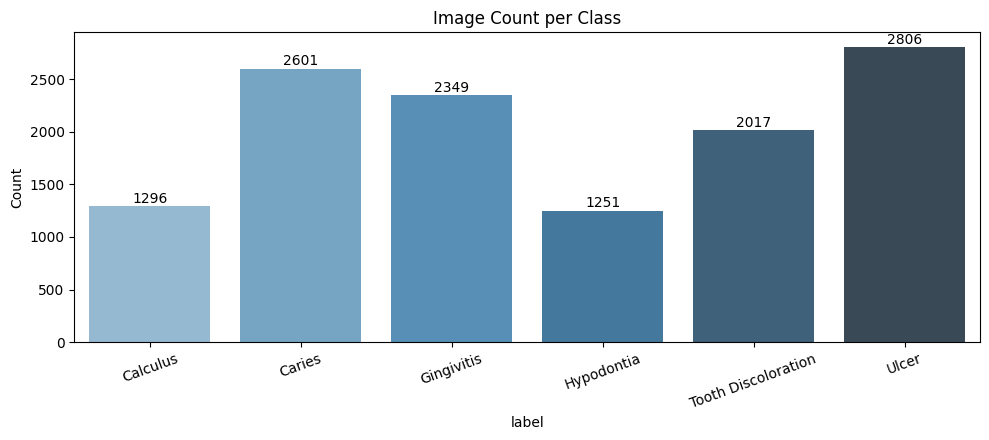

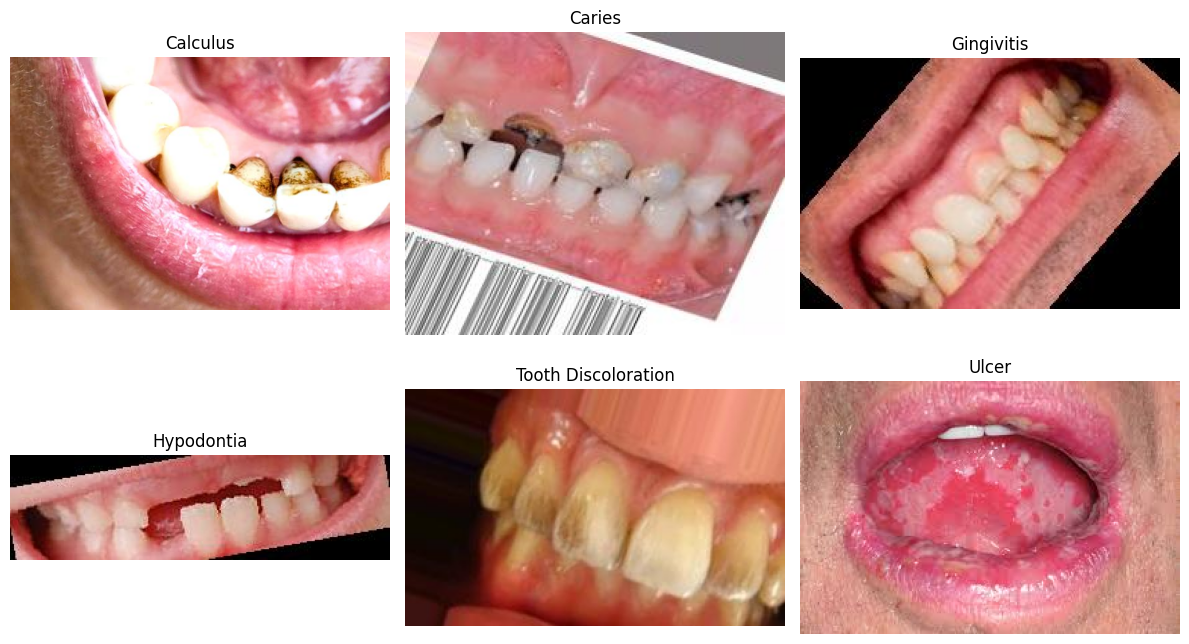

In [4]:
counts = df["label"].value_counts().reindex(class_names)
print(counts)
print(f"Imbalance Ratio: {counts.max() / counts.min():.2f}")

plt.figure(figsize=(10, 4.5))
ax = sns.barplot(x=counts.index, y=counts.values, palette="Blues_d")
for i, v in enumerate(counts.values):
    ax.text(i, v + 30, str(v), ha="center", fontsize=10)
plt.title("Image Count per Class")
plt.ylabel("Count")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(12, 7))
axes = axes.flatten()
for idx, cls in enumerate(class_names):
    sample_path = df[df["label"] == cls]["filepath"].sample(1, random_state=SEED).values[0]
    axes[idx].imshow(Image.open(sample_path).convert("RGB"))
    axes[idx].set_title(cls)
    axes[idx].axis("off")
plt.tight_layout()
plt.show()

## Data Splitting & Preprocessing

In [5]:
train_df, temp_df = train_test_split(
    df, test_size=0.30, stratify=df["label_id"], random_state=SEED
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df["label_id"], random_state=SEED
)

weights_arr = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(NUM_CLASSES),
    y=train_df["label_id"].values
)
class_weights = {i: float(w) for i, w in enumerate(weights_arr)}

AUTOTUNE = tf.data.AUTOTUNE

data_aug = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.12),
    layers.RandomContrast(0.1)
])

def decode_image(path, label):
    raw = tf.io.read_file(path)
    img = tf.io.decode_image(raw, channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    img = tf.image.resize(img, IMG_SIZE)
    img = tf.cast(img, tf.float32)
    return img, label

def build_dataset(dataframe, is_train=False):
    ds = tf.data.Dataset.from_tensor_slices(
        (dataframe["filepath"].values, dataframe["label_id"].values)
    )
    ds = ds.map(decode_image, num_parallel_calls=AUTOTUNE)
    if is_train:
        ds = ds.shuffle(1000, seed=SEED)
    ds = ds.batch(BATCH_SIZE)
    if is_train:
        ds = ds.map(lambda x, y: (data_aug(x, training=True), y), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

train_ds = build_dataset(train_df, is_train=True)
val_ds = build_dataset(val_df, is_train=False)
test_ds = build_dataset(test_df, is_train=False)

print(f"Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")

Train: 8624 | Val: 1848 | Test: 1848


## Training Utilities

In [6]:
def get_callbacks(save_name):
    return [
        callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
        callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, min_lr=1e-6),
        callbacks.ModelCheckpoint(save_name, monitor="val_accuracy", save_best_only=True)
    ]

def evaluate_model(model, model_name, dataset=test_ds):
    y_true = []
    y_pred = []

    start = time.time()
    for batch_imgs, batch_labels in dataset:
        probs = model.predict(batch_imgs, verbose=0)
        preds = np.argmax(probs, axis=1)
        y_pred.extend(preds)
        y_true.extend(batch_labels.numpy())
    elapsed = time.time() - start

    acc = accuracy_score(y_true, y_pred) * 100
    f1 = f1_score(y_true, y_pred, average="weighted")
    ms_per_img = (elapsed / len(y_true)) * 1000

    print(f"\n{model_name} Test Report")
    print(classification_report(y_true, y_pred, target_names=class_names))

    summary = {
        "Model": model_name,
        "Test Accuracy (%)": round(acc, 2),
        "Weighted F1": round(f1, 4),
        "Inference (ms/img)": round(ms_per_img, 2)
    }
    return summary, np.array(y_true), np.array(y_pred)

def plot_training_curves(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history.history["accuracy"], label="Train Acc")
    axes[0].plot(history.history["val_accuracy"], label="Val Acc")
    axes[0].set_title(f"{title} - Accuracy")
    axes[0].set_xlabel("Epoch")
    axes[0].legend()

    axes[1].plot(history.history["loss"], label="Train Loss")
    axes[1].plot(history.history["val_loss"], label="Val Loss")
    axes[1].set_title(f"{title} - Loss")
    axes[1].set_xlabel("Epoch")
    axes[1].legend()

    plt.tight_layout()
    plt.show()

all_results = []

## Custom CNN

Epoch 1/15
270/270 ━━━━━━━━━━━━━━━━━━━━ 131s 410ms/step - accuracy: 0.4381 - loss: 1.3860 - val_accuracy: 0.2468 - val_loss: 3.1698 - learning_rate: 0.0010
Epoch 2/15
270/270 ━━━━━━━━━━━━━━━━━━━━ 110s 354ms/step - accuracy: 0.5291 - loss: 1.1483 - val_accuracy: 0.4637 - val_loss: 1.3557 - learning_rate: 0.0010
Epoch 3/15
270/270 ━━━━━━━━━━━━━━━━━━━━ 96s 349ms/step - accuracy: 0.5628 - loss: 1.0588 - val_accuracy: 0.4778 - val_loss: 1.1429 - learning_rate: 0.0010
Epoch 4/15
270/270 ━━━━━━━━━━━━━━━━━━━━ 95s 345ms/step - accuracy: 0.5885 - loss: 0.9925 - val_accuracy: 0.5547 - val_loss: 1.3279 - learning_rate: 0.0010
Epoch 5/15
270/270 ━━━━━━━━━━━━━━━━━━━━ 144s 354ms/step - accuracy: 0.6171 - loss: 0.9446 - val_accuracy: 0.4659 - val_loss: 1.2113 - learning_rate: 0.0010
Epoch 6/15
270/270 ━━━━━━━━━━━━━━━━━━━━ 141s 352ms/step - accuracy: 0.6489 - loss: 0.8446 - val_accuracy: 0.6510 - val_loss: 0.8639 - learning_rate: 3.0000e-04
Epoch 7/15
270/270 ━━━━━━━━━━━━━━━━━━━━ 96s 346ms/step - accur

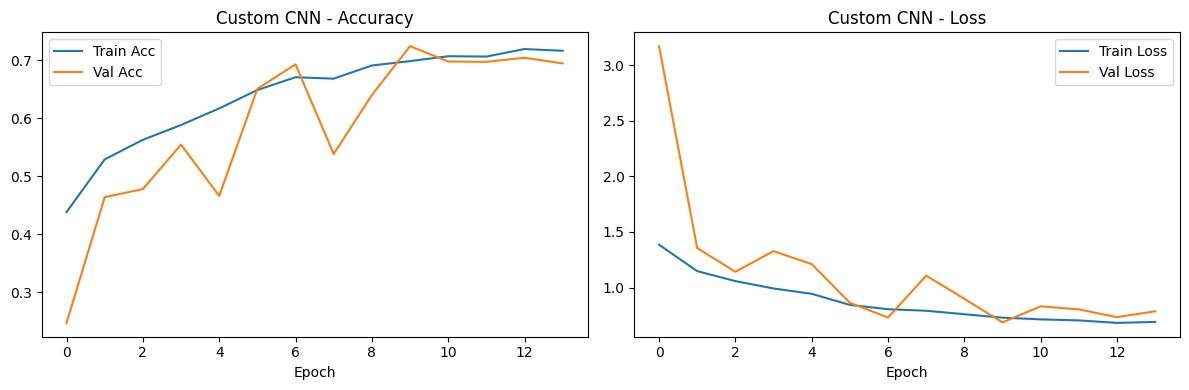


Custom CNN Test Report
                     precision    recall  f1-score   support

           Calculus       0.47      0.82      0.60       195
             Caries       0.82      0.60      0.69       390
         Gingivitis       0.78      0.56      0.65       352
         Hypodontia       0.68      0.86      0.76       188
Tooth Discoloration       0.71      0.80      0.75       302
              Ulcer       0.93      0.86      0.89       421

           accuracy                           0.73      1848
          macro avg       0.73      0.75      0.72      1848
       weighted avg       0.77      0.73      0.74      1848



In [7]:
def build_custom_cnn(dropout_rate=0.4, lr=1e-3):
    inputs = layers.Input(shape=(*IMG_SIZE, 3))
    x = layers.Rescaling(1.0 / 255.0)(inputs)

    for filters in [32, 64, 128, 256]:
        x = layers.Conv2D(filters, (3, 3), padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        x = layers.MaxPooling2D((2, 2))(x)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout_rate)(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(dropout_rate * 0.5)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

    model = models.Model(inputs, outputs, name="Custom_CNN")
    model.compile(
        optimizer=optimizers.Adam(learning_rate=lr),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

custom_cnn = build_custom_cnn(dropout_rate=0.4, lr=1e-3)
hist_cnn = custom_cnn.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    class_weight=class_weights,
    callbacks=get_callbacks("custom_cnn.keras")
)

plot_training_curves(hist_cnn, "Custom CNN")
cnn_res, cnn_y_true, cnn_y_pred = evaluate_model(custom_cnn, "Custom CNN")
all_results.append(cnn_res)

## Hyperparameter Tuning

In [8]:
def build_mobilenet(dropout_rate=0.3, lr=1e-3):
    inputs = layers.Input(shape=(*IMG_SIZE, 3))
    x = layers.Rescaling(1.0 / 127.5, offset=-1.0)(inputs)

    base = MobileNetV2(include_top=False, weights="imagenet", input_tensor=x)
    base.trainable = False

    x = layers.GlobalAveragePooling2D()(base.output)
    x = layers.Dropout(dropout_rate)(x)
    x = layers.Dense(128, activation="relu")(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

    model = models.Model(inputs, outputs, name="MobileNetV2_Oral")
    model.compile(
        optimizer=optimizers.Adam(learning_rate=lr),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model, base

search_space = [
    {"lr": 1e-3, "dropout": 0.3},
    {"lr": 1e-3, "dropout": 0.5},
    {"lr": 3e-4, "dropout": 0.3}
]

tuning_log = []
for cfg in search_space:
    m, _ = build_mobilenet(dropout_rate=cfg["dropout"], lr=cfg["lr"])
    h = m.fit(train_ds, validation_data=val_ds, epochs=3, class_weight=class_weights, verbose=1)
    best_val = max(h.history["val_accuracy"])
    tuning_log.append({"lr": cfg["lr"], "dropout": cfg["dropout"], "val_accuracy": round(best_val * 100, 2)})

tuning_df = pd.DataFrame(tuning_log)
display(tuning_df)

best_cfg = tuning_df.loc[tuning_df["val_accuracy"].idxmax()]
print("Best Hyperparameters:", dict(best_cfg))

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/3
270/270 ━━━━━━━━━━━━━━━━━━━━ 151s 462ms/step - accuracy: 0.6532 - loss: 0.8804 - val_accuracy: 0.7819 - val_loss: 0.5403
Epoch 2/3
270/270 ━━━━━━━━━━━━━━━━━━━━ 94s 344ms/step - accuracy: 0.7444 - loss: 0.6336 - val_accuracy: 0.8074 - val_loss: 0.4949
Epoch 3/3
270/270 ━━━━━━━━━━━━━━━━━━━━ 94s 343ms/step - accuracy: 0.7738 - loss: 0.5669 - val_accuracy: 0.8339 - val_loss: 0.4460
Epoch 1/3
270/270 ━━━━━━━━━━━━━━━━━━━━ 112s 372ms/step - accuracy: 0.6113 - loss: 0.9824 - val_accuracy: 0.7614 - val_loss: 0.5995
Epoch 2/3
270/270 ━━━━━━━━━━━━━━━━━━━━ 130s 345ms/step - accuracy: 0.7032 - loss: 0.7461 - val_accuracy: 0.7960 - val_loss: 0.5308
Epoch 3/3
270/270 ━━━━━━━━━━━━━━━━━━━━ 91s 332ms/step - accuracy: 0.7312 - loss: 0.6625 - val_accuracy: 0.8187 - val_loss: 0.4778
Epoch 1/3
270/270 ━━━━━━━━━━━━━━━━━━━━ 112s 369ms/step - accuracy: 0.5951 - loss: 1.0354 - val_accuracy: 0.7657 - val_loss: 0.6175
Epoch 2/3
270/270 ━━━━━━━━━━━━━━━━━━━

,lr,dropout,val_accuracy
0,0.0010,0.3,83.39
1,0.0010,0.5,81.87
2,0.0003,0.3,80.09


Best Hyperparameters: {'lr': np.float64(0.001), 'dropout': np.float64(0.3), 'val_accuracy': np.float64(83.39)}


## MobileNetV2

Epoch 1/8
270/270 ━━━━━━━━━━━━━━━━━━━━ 113s 377ms/step - accuracy: 0.6513 - loss: 0.8869 - val_accuracy: 0.7435 - val_loss: 0.6419 - learning_rate: 0.0010
Epoch 2/8
270/270 ━━━━━━━━━━━━━━━━━━━━ 95s 345ms/step - accuracy: 0.7498 - loss: 0.6353 - val_accuracy: 0.8052 - val_loss: 0.4936 - learning_rate: 0.0010
Epoch 3/8
270/270 ━━━━━━━━━━━━━━━━━━━━ 95s 348ms/step - accuracy: 0.7715 - loss: 0.5758 - val_accuracy: 0.8133 - val_loss: 0.4768 - learning_rate: 0.0010
Epoch 4/8
270/270 ━━━━━━━━━━━━━━━━━━━━ 95s 345ms/step - accuracy: 0.7914 - loss: 0.5216 - val_accuracy: 0.8144 - val_loss: 0.4343 - learning_rate: 0.0010
Epoch 5/8
270/270 ━━━━━━━━━━━━━━━━━━━━ 95s 347ms/step - accuracy: 0.8075 - loss: 0.4727 - val_accuracy: 0.8306 - val_loss: 0.4098 - learning_rate: 0.0010
Epoch 6/8
270/270 ━━━━━━━━━━━━━━━━━━━━ 142s 348ms/step - accuracy: 0.8156 - loss: 0.4551 - val_accuracy: 0.8387 - val_loss: 0.3956 - learning_rate: 0.0010
Epoch 7/8
270/270 ━━━━━━━━━━━━━━━━━━━━ 143s 350ms/step - accuracy: 0.8275 

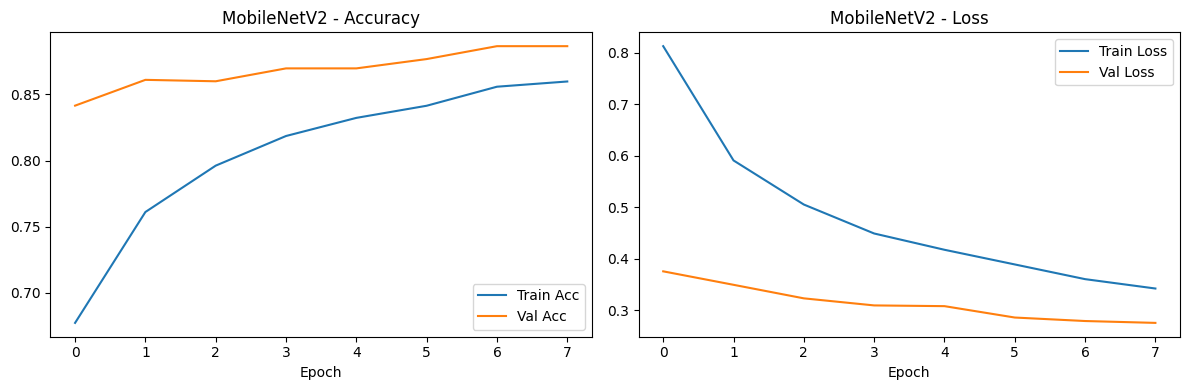


MobileNetV2 Test Report
                     precision    recall  f1-score   support

           Calculus       0.64      0.80      0.71       195
             Caries       0.94      0.91      0.92       390
         Gingivitis       0.82      0.75      0.79       352
         Hypodontia       0.94      0.94      0.94       188
Tooth Discoloration       0.92      0.89      0.90       302
              Ulcer       0.98      0.99      0.98       421

           accuracy                           0.89      1848
          macro avg       0.87      0.88      0.87      1848
       weighted avg       0.89      0.89      0.89      1848



In [9]:
mobilenet_model, mobilenet_base = build_mobilenet(
    dropout_rate=float(best_cfg["dropout"]),
    lr=float(best_cfg["lr"])
)

hist_mb_head = mobilenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    class_weight=class_weights,
    callbacks=get_callbacks("mobilenet_best.keras")
)

mobilenet_base.trainable = True
for layer in mobilenet_base.layers[:-40]:
    layer.trainable = False

mobilenet_model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

hist_mb_ft = mobilenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    class_weight=class_weights,
    callbacks=get_callbacks("mobilenet_best.keras")
)

plot_training_curves(hist_mb_ft, "MobileNetV2")
mb_res, mb_y_true, mb_y_pred = evaluate_model(mobilenet_model, "MobileNetV2")
all_results.append(mb_res)

## DenseNet121

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/8
270/270 ━━━━━━━━━━━━━━━━━━━━ 293s 841ms/step - accuracy: 0.5920 - loss: 1.0524 - val_accuracy: 0.7376 - val_loss: 0.6463 - learning_rate: 0.0010
Epoch 2/8
270/270 ━━━━━━━━━━━━━━━━━━━━ 99s 360ms/step - accuracy: 0.6938 - loss: 0.7562 - val_accuracy: 0.8052 - val_loss: 0.5022 - learning_rate: 0.0010
Epoch 3/8
270/270 ━━━━━━━━━━━━━━━━━━━━ 98s 359ms/step - accuracy: 0.7285 - loss: 0.6949 - val_accuracy: 0.7689 - val_loss: 0.5684 - learning_rate: 0.0010
Epoch 4/8
270/270 ━━━━━━━━━━━━━━━━━━━━ 98s 354ms/step - accuracy: 0.7273 - loss: 0.6734 - val_accuracy: 0.7960 - val_loss: 0.5108 - learning_rate: 0.0010
Epoch 5/8
270/270 ━━━━━━━━━━━━━━━━━━━━ 99s 361ms/step - accuracy: 0.7513 - loss: 0.6262 - val_accuracy: 0.8393 - val_loss: 0.4405 - learning_rate: 3.0000e-04
Epoch 6/8
270/270 ━━━━━━━━━━━━━━━━━━━━ 141s 357ms/step - accuracy: 0.7600 - loss: 0.6003 - val_accuracy: 0.8409 - val_loss: 0.4333 - learning_rate: 3.0000e-04
Epoch 7/8
270/2

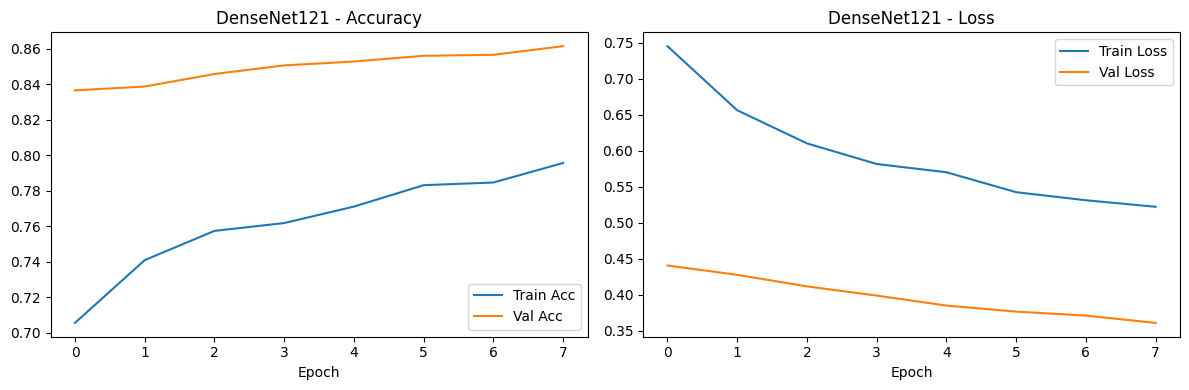


DenseNet121 Test Report
                     precision    recall  f1-score   support

           Calculus       0.59      0.81      0.68       195
             Caries       0.93      0.87      0.90       390
         Gingivitis       0.82      0.68      0.75       352
         Hypodontia       0.96      0.93      0.94       188
Tooth Discoloration       0.85      0.93      0.88       302
              Ulcer       0.99      0.96      0.97       421

           accuracy                           0.86      1848
          macro avg       0.86      0.86      0.85      1848
       weighted avg       0.88      0.86      0.87      1848



In [10]:
def build_densenet(dropout_rate=0.3, lr=1e-3):
    inputs = layers.Input(shape=(*IMG_SIZE, 3))
    x = layers.Rescaling(1.0 / 255.0)(inputs)
    x = layers.Normalization(
        mean=[0.485, 0.456, 0.406],
        variance=[0.229**2, 0.224**2, 0.225**2]
    )(x)

    base = DenseNet121(include_top=False, weights="imagenet", input_tensor=x)
    base.trainable = False

    x = layers.GlobalAveragePooling2D()(base.output)
    x = layers.Dropout(dropout_rate)(x)
    x = layers.Dense(128, activation="relu")(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

    model = models.Model(inputs, outputs, name="DenseNet121_Oral")
    model.compile(
        optimizer=optimizers.Adam(learning_rate=lr),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model, base

densenet_model, densenet_base = build_densenet(dropout_rate=0.3, lr=1e-3)

hist_dn_head = densenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    class_weight=class_weights,
    callbacks=get_callbacks("densenet_best.keras")
)

densenet_base.trainable = True
for layer in densenet_base.layers[:-60]:
    layer.trainable = False

densenet_model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

hist_dn_ft = densenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    class_weight=class_weights,
    callbacks=get_callbacks("densenet_best.keras")
)

plot_training_curves(hist_dn_ft, "DenseNet121")
dn_res, dn_y_true, dn_y_pred = evaluate_model(densenet_model, "DenseNet121")
all_results.append(dn_res)

## Model Comparison

,Model,Test Accuracy (%),Weighted F1,Inference (ms/img)
0,MobileNetV2,88.53,0.8869,8.11
1,DenseNet121,86.36,0.8661,23.34
2,Custom CNN,73.32,0.7362,4.67


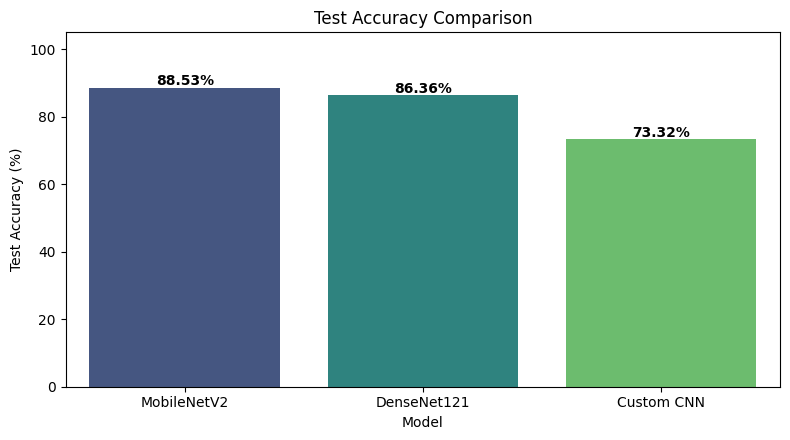

Best Model: MobileNetV2


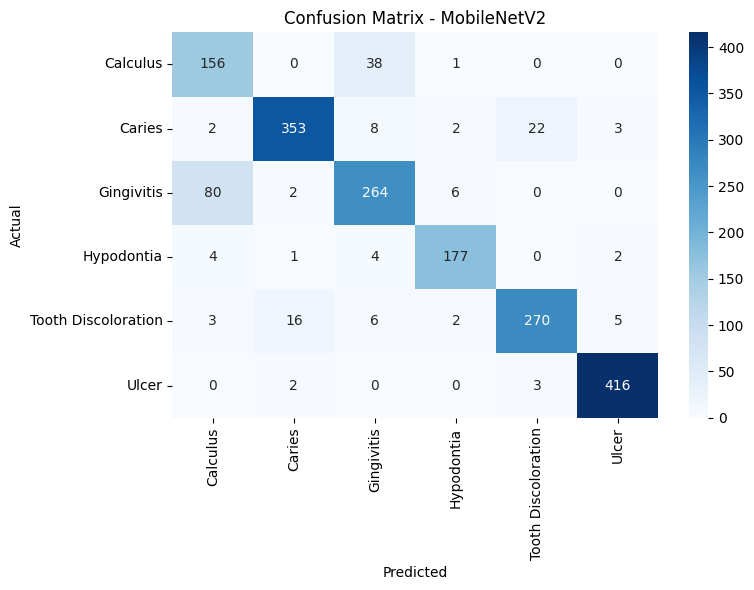

In [11]:
comparison_df = pd.DataFrame(all_results).sort_values(by="Test Accuracy (%)", ascending=False).reset_index(drop=True)
display(comparison_df)

plt.figure(figsize=(8, 4.5))
ax = sns.barplot(data=comparison_df, x="Model", y="Test Accuracy (%)", palette="viridis")
for i, v in enumerate(comparison_df["Test Accuracy (%)"]):
    ax.text(i, v + 0.8, f"{v:.2f}%", ha="center", fontweight="bold")
plt.ylim(0, 105)
plt.title("Test Accuracy Comparison")
plt.tight_layout()
plt.show()

best_name = comparison_df.loc[0, "Model"]
print("Best Model:", best_name)

model_map = {
    "Custom CNN": ("custom_cnn.keras", cnn_y_true, cnn_y_pred),
    "MobileNetV2": ("mobilenet_best.keras", mb_y_true, mb_y_pred),
    "DenseNet121": ("densenet_best.keras", dn_y_true, dn_y_pred)
}

best_model_file, best_true, best_pred = model_map[best_name]

cm = confusion_matrix(best_true, best_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"Confusion Matrix - {best_name}")
plt.tight_layout()
plt.show()

## Deployment

In [12]:
import gradio as gr

deployed_model = keras.models.load_model(best_model_file)

disease_notes = {
    "Calculus": "Hardened dental plaque (tartar) buildup near the gum line. Professional dental scaling is advised.",
    "Caries": "Tooth decay caused by enamel breakdown. Early dental checkup and restoration are recommended.",
    "Gingivitis": "Gum inflammation often linked to plaque accumulation. Regular brushing, flossing, and dental visits help.",
    "Hypodontia": "Developmental absence of one or more teeth. Orthodontic or prosthodontic consultation is recommended.",
    "Tooth Discoloration": "Staining or color change in teeth caused by surface or internal factors.",
    "Ulcer": "Localized sore on the oral mucosa. Persistent ulcers lasting over two weeks should be examined by a specialist."
}

def predict_oral_disease(image):
    if image is None:
        return {}, "Please upload an oral image first."

    img = image.convert("RGB").resize(IMG_SIZE)
    arr = np.expand_dims(np.array(img, dtype=np.float32), axis=0)
    probs = deployed_model.predict(arr, verbose=0)[0]

    prob_dict = {class_names[i]: float(probs[i]) for i in range(NUM_CLASSES)}
    top_idx = int(np.argmax(probs))
    top_class = class_names[top_idx]
    confidence = probs[top_idx] * 100

    info_text = (
        f"Predicted Condition: {top_class} ({confidence:.2f}%)\n\n"
        f"Info: {disease_notes.get(top_class, '')}\n\n"
        f"Note: Educational project only, not a substitute for medical diagnosis."
    )
    return prob_dict, info_text

with gr.Blocks(title="Oral Disease Classifier") as demo:
    gr.Markdown(f"## Oral Disease Image Classification\nModel: **{best_name}**")

    with gr.Row():
        with gr.Column():
            img_input = gr.Image(type="pil", label="Upload Oral Image")
            run_btn = gr.Button("Predict", variant="primary")
        with gr.Column():
            label_output = gr.Label(num_top_classes=6, label="Class Probabilities")
            notes_output = gr.Textbox(label="Prediction Summary", lines=6, interactive=False)

    run_btn.click(fn=predict_oral_disease, inputs=img_input, outputs=[label_output, notes_output])

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://43f211ba22b821d83c.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
